In [1]:
push!(LOAD_PATH,"./")
push!(LOAD_PATH,"julia/")
include("model.jl")
using DataFrames, CSV

In [3]:
# A = good
# B = bad
strategies = Dict()
strategies["always_inactive"] = Strategy(0,1,0,1,0,0,0,0,0,0)
strategies["always_active"] = Strategy(1,0,1,0,0,0,0,0,0,0)
strategies["naive_flexible"] = Strategy(1,0,0,1,0,0,0,0,0,0)
strategies["positive_feedback_active"] = Strategy(1,0,0,1,1,0,0,0,0,0)
strategies["negative_feedback_active"] = Strategy(1,0,0,1,0,1,0,0,0,0)
strategies["positive_feedback_inactive"] = Strategy(1,0,0,1,0,0,0,1,0,0)
strategies["negative_feedback_inactive"] = Strategy(1,0,0,1,0,0,1,0,0,0)

Strategy(1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0)

In [ ]:
alpha = collect(0.1:0.1:12)
beta = [0,1,4,10]
gamma = [0]
delta = [1e-6]
lambda = [1]
b = 2 .^collect(-4:0.1:4)
c = [1]
n = [0, 5]


d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))
CSV.write("results/alpha_bc.csv",d)

In [ ]:
alpha = collect(0.1:0.1:12)
beta = [0,1,4,10]
gamma = [0]
delta = [1e-6]
lambda = [1]
b = 2 .^collect(-4:0.1:4)
c = [1]
n = [0, 5]


d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))
CSV.write("results/alpha_bc.csv",d)

77760-element Vector{Float64}:
 -2.3437265627343726e-6
 -1.1718691406542968e-6
 -7.812473958420138e-7
 -5.85936035159912e-7
 -4.68749062501875e-7
 -3.906243489594184e-7
 -3.3482095025578535e-7
 -2.929683837895202e-7
 -2.604163773151363e-7
 -2.3437476562523433e-7
  ⋮
  7.51618551185478
  7.518786048743185
  7.521363508852491
  7.523918007294154
  7.5264496696169685
  7.5289586308406
  7.5314450345589545
  7.533909032108659
  7.5363507817978705

In [21]:
alpha = 10 .^ collect(-1:0.02:2)
beta = [0,1,4,10]
gamma = [0]
delta = [1e-6]
lambda = [1]
b = 2 .^collect(-4:0.1:4)
c = [1]
n = [0, 5]

d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))
CSV.write("results/alpha_bc_log10.csv",d)

"results/alpha_bc_log10.csv"

In [4]:
lambda = 10 .^ collect(-2:0.05:2)
beta = [0,1,4,10]
gamma = [0]
delta = [1e-6]
alpha = [1]
b = 2 .^collect(-4:0.1:4)
c = [1]
n = [0, 5]

d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))
CSV.write("results/lambda_bc_log10.csv",d)

"results/lambda_bc_log10.csv"

In [24]:
using DataFrames, CSV

alpha = 10 .^ collect(-2:0.02:2)
beta = collect(0:0.1:12)
lambda = [0.1,1,10]
gamma = [0]
delta = [1e-6]
b = [1,2,4]
c = [1]
n = [0, 5]

d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/alpha_beta_log10.csv",d) # takes 15 mins

"results/alpha_beta_log10.csv"

In [23]:
using DataFrames, CSV

alpha = [1,3,5]
beta = collect(0:0.05:12)
lambda = 10 .^ collect(-2:0.05:2)
gamma = [0]
delta = [1e-6]
b = [1,2,4]
c = [1]
n = [0,5]


d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/optimal_beta_by_lambda_log10.csv",d) 

"results/optimal_beta_by_lambda_log10.csv"

In [ ]:
using DataFrames, CSV

alpha = [3]
beta = collect(0:0.05:12)
lambda = 10 .^ collect(-2:0.05:2)
gamma = [0]
delta = [1e-6]
b = [1,2,4]
c = [1]
n = [0,2,3,4,5,6,7,8,9,10,20,50]


d = DataFrame(collect(Iterators.product(alpha,beta,gamma,delta,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:delta,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row ->fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/optimal_beta_by_lambda_log10.csv",d) 

In [ ]:
using DataFrames, CSV

alpha = collect(1:1:12)
beta = collect(0:0.05:12)
lambda = 10 .^ collect(-2:0.05:2)
gamma = [1e-6]
b = [0.25,0.5,1,2,4]
c = [1]
n = [0,5]

d = DataFrame(collect(Iterators.product(alpha,beta,gamma,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row -> fitness(row.n,row.alpha,row.beta,row.gamma,row.lambda,s,row.b,row.c)[1], eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/optimal_beta_by_lambda.csv",d) #takes 46 minutes

"results/optimal_beta_by_lambda.csv"

In [9]:
using DataFrames, CSV

alpha = collect(0:0.002:3)
lambda = 10 .^ collect(-2:0.05:2)
k = [4, 12]
gamma = [0]
delta = [1e-6]
b = [2]
c = [1]
n = [5]

d = DataFrame(collect(Iterators.product(alpha,gamma,delta,lambda,b,c,n,k)))
rename!(d,[:alpha,:gamma,:delta,:lambda,:b,:c,:n,:k])
d.beta = 12.0 .- d.alpha .* d.k
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row -> fitness(Dict(String(k) => v for (k, v) in pairs(row)), s), eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/alpha_beta_tradeoff.csv",d)

"results/alpha_beta_tradeoff.csv"

In [18]:
using DataFrames, CSV

alpha = collect(0:0.05:12)
lambda = 10 .^ collect(-2:0.1:2)
k = [1, 2, 4, 5, 10]
gamma = [1e-6]
b = [1, 2, 4, 8, 16]
c = [1]
n = [2,3,4,5,10,20]

d = DataFrame(collect(Iterators.product(alpha,gamma,lambda,b,c,n,k)))
rename!(d,[:alpha,:gamma,:lambda,:b,:c,:n,:k])
d.beta = (12.0 .- d.alpha) .* d.k
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row -> fitness(row.n,row.alpha,row.beta,row.gamma,row.lambda,s,row.b,row.c)[1], eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/alpha_beta_tradeoff_group_size.csv",d)

"results/alpha_beta_tradeoff_group_size.csv"

In [16]:
using DataFrames, CSV

alpha = collect(0.1:0.1:12)
beta0 = [1]
lambda = 10 .^ collect(-2:0.1:2)
gamma = [1e-6]
b = [1, 2, 4, 8, 16]
c = [1]
n = [2,3,4,5,6,7,8,9,10]

d = DataFrame(collect(Iterators.product(alpha,beta0,gamma,lambda,b,c,n)))
rename!(d,[:alpha,:beta0,:gamma,:lambda,:b,:c,:n])
d.beta = d.beta0 .* (d.n .- 1)
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row -> fitness(row.n,row.alpha,row.beta,row.gamma,row.lambda,s,row.b,row.c)[1], eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/group_size_1.csv",d)

"results/group_size_1.csv"

In [ ]:
using DataFrames, CSV

alpha = collect(0.1:0.1:12)
beta0 = [1]
lambda = 10 .^ collect(-2:0.1:2)
gamma = [1e-6]
b = [1, 2, 4, 8, 16]
c = [1]
n = [2,3,4,5,6,7,8,9,10]

d = DataFrame(collect(Iterators.product(alpha,beta0,gamma,lambda,b,c,n)))
rename!(d,[:alpha,:beta0,:gamma,:lambda,:b,:c,:n])
d.beta = d.beta0 .* (d.n .- 1)
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row -> fitness(row.n,row.alpha,row.beta,row.gamma,row.lambda,s,row.b,row.c)[1], eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/group_size_1.csv",d)

In [ ]:
using DataFrames, CSV

alpha = collect(0:0.1:12)
beta = collect(0:0.1:12)
lambda = [1]
gamma = [1e-6]
b = [0.25,0.5,1,2,4]
c = [1]
n = [2,3,4,5,10]

d = DataFrame(collect(Iterators.product(alpha,beta,gamma,lambda,b,c,n)))
rename!(d,[:alpha,:beta,:gamma,:lambda,:b,:c,:n])
for (name,s) in strategies
    d[!, name * "_fitness"] = map(row -> fitness(row.n,row.alpha,row.beta,row.gamma,row.lambda,s,row.b,row.c)[1], eachrow(d))
end
d.winner = map(row -> collect(keys(strategies))[argmax([row[name * "_fitness"] for name in keys(strategies)])],eachrow(d))
d.winner_fitness = map(row -> maximum([row[name * "_fitness"] for name in keys(strategies)]),eachrow(d))

CSV.write("results/alpha_beta_2.csv",d)

InterruptException: InterruptException:

In [5]:
using DataFrames, CSV

alpha = collect(0:0.05:12)
beta = collect(0:0.1:24)
lambda = [1]
yA = [1,2,4]
yB = [1]
n = [2,3,4,5,10,25]
gamma = [1e-6]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB,n,gamma)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB,:n,:gamma])
d.naive_flexible_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test2f.csv",d)

"results/test2f.csv"

In [6]:
using DataFrames, CSV

alpha = collect(0:0.1:12)
beta = collect(0:0.1:12)
lambda = [1]
yA = [0.25,0.5,1,2]
yB = [1]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB])
d.naive_flexible_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.negative_feedback_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,negative_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","negative_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.negative_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test3.csv",d)

"results/test3.csv"

In [3]:
using DataFrames, CSV

alpha = collect(0:0.05:12)
beta = collect(0:0.1:24)
lambda = [1]
yA = [1,2,4]
yB = [1]
n = [2,3,4,5,10,25]
gamma = [1e-6]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB,n,gamma)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB,:n,:gamma])
d.naive_flexible_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,naive_flexible,row.yA,row.yB,false), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,positive_feedback,row.yA,row.yB,false), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test2g.csv",d)

"results/test2g.csv"

In [5]:
using DataFrames, CSV

alpha = collect(0:0.1:12)
beta = [0.4,4,40]
lambda = [1]
yA = [1,2,4]
yB = [1]
n = collect(2:1:50)
gamma = [1e-6]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB,n,gamma)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB,:n,:gamma])
d.naive_flexible_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,naive_flexible,row.yA,row.yB,false), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,positive_feedback,row.yA,row.yB,false), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test2h.csv",d)

"results/test2h.csv"

In [22]:
using DataFrames, CSV
resolution = 50
limit = 10
solutions = [limit.*(p,q,-p-q)./resolution for p in (-2*resolution):(2*resolution) for q in (-2*resolution):(2*resolution) if (abs(-p-q) <= resolution && abs(p+2*q) <= resolution && abs(p-q) <= resolution && abs(2*p+q)<=resolution)]
d = DataFrame(solutions, [:p,:q,:r])
d.alpha .= 2 .^d.p ./ (1 .+2 .^(d.p) .+ 2 .^(d.p+d.q))
d.beta .= 2 .^(d.p+d.q) ./ (1 .+2 .^(d.p) .+ 2 .^(d.p+d.q))
d.lambda .= 1 ./ (1 .+2 .^(d.p) .+ 2 .^(d.p+d.q))
d.yA .= 2
d.yB .= 1  
d.naive_flexible_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test2triangle2.csv",d)

"results/test2triangle2.csv"

In [112]:
using DataFrames, CSV
n = 100
solutions = [(a,b,n-a-b)./n for a in 1:(n-2) for b in 1:(n-2) if n-a-b >= 1]
d = DataFrame(solutions, [:alpha,:beta,:lambda])
d.yA .= 2
d.yB .= 1  
d.naive_flexible_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test2triangle.csv",d)



"results/test2triangle.csv"

In [6]:
using DataFrames, CSV
n = 100

solutions = [(a,b,n-a-b)./n for a in 1:(n-2) for b in 1:(n-2) if n-a-b >= 1]


ds = DataFrame[]
for group_size in [1,2,3,4,5,10,25,100]
    d = DataFrame(solutions, [:alpha,:beta,:lambda])
    d.yA .= 2
    d.yB .= 1  
    d.gamma .= 1e-6
    d.n .= group_size
    d.naive_flexible_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
    d.positive_feedback_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
    d.inactive_fitness = 0.5*d.yB
    d.active_fitness = 0.5*d.yA
    d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))
    push!(ds, d)
end

d = vcat(ds...)

CSV.write("results/test2trianglefinite.csv",d)

"results/test2trianglefinite.csv"

In [ ]:
using DataFrames, CSV
n = 100

solutions = [(a,b,n-a-b)./n for a in 1:(n-2) for b in 1:(n-2) if n-a-b >= 1]


ds = DataFrame[]
for group_size in [1,2,3,4,5,10,25,100]
    d = DataFrame(solutions, [:alpha,:beta,:lambda])
    d.yA .= 2
    d.yB .= 1  
    d.gamma .= 1e-6
    d.n .= group_size
    d.naive_flexible_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
    d.positive_feedback_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta,row.gamma,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
    d.inactive_fitness = 0.5*d.yB
    d.active_fitness = 0.5*d.yA
    d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))
    push!(ds, d)
end

d = vcat(ds...)

CSV.write("results/test2trianglefinite.csv",d)

In [105]:
solutions

91-element Vector{Tuple{Float64, Float64, Float64}}:
 (0.06666666666666667, 0.06666666666666667, 0.8666666666666667)
 (0.06666666666666667, 0.13333333333333333, 0.8)
 (0.06666666666666667, 0.2, 0.7333333333333333)
 (0.06666666666666667, 0.26666666666666666, 0.6666666666666666)
 (0.06666666666666667, 0.3333333333333333, 0.6)
 (0.06666666666666667, 0.4, 0.5333333333333333)
 (0.06666666666666667, 0.4666666666666667, 0.4666666666666667)
 (0.06666666666666667, 0.5333333333333333, 0.4)
 (0.06666666666666667, 0.6, 0.3333333333333333)
 (0.06666666666666667, 0.6666666666666666, 0.26666666666666666)
 ⋮
 (0.6666666666666666, 0.13333333333333333, 0.2)
 (0.6666666666666666, 0.2, 0.13333333333333333)
 (0.6666666666666666, 0.26666666666666666, 0.06666666666666667)
 (0.7333333333333333, 0.06666666666666667, 0.2)
 (0.7333333333333333, 0.13333333333333333, 0.13333333333333333)
 (0.7333333333333333, 0.2, 0.06666666666666667)
 (0.8, 0.06666666666666667, 0.13333333333333333)
 (0.8, 0.13333333333333333, 0.0

In [96]:
using DataFrames, CSV

alpha = collect(0:1:100)
beta = collect(0:1:100)
lambda = [1]
yA = [1,2,4]
yB = [1]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB])
d.naive_flexible_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test2z.csv",d)

"results/test2z.csv"

In [59]:
using DataFrames, CSV

alpha = collect(0:0.1:8)
beta = [0,1,2,3,4]
lambda = [1]
yA = 2 .^collect(-3:0.1:3)
yB = [1]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB])
d.naive_flexible_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessInfiniteModel(row.alpha,row.beta,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test3.csv",d)

"results/test3.csv"

In [91]:
using DataFrames, CSV

alpha = collect(0:0.1:8)
beta = [0,1,2,3,4]
lambda = [1]
yA = 2 .^collect(-3:0.1:3)
yB = [1]
n = [1,2,3,4,5,25]
gamma = [1e-6]

d = DataFrame(collect(Iterators.product(alpha,beta,lambda,yA,yB,n,gamma)))
rename!(d,[:alpha,:beta,:lambda,:yA,:yB,:n,:gamma])
d.naive_flexible_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta/row.n,row.gamma,row.lambda,naive_flexible,row.yA,row.yB), eachrow(d))
d.positive_feedback_fitness = map(row -> fitnessFiniteModel(row.n,row.alpha,row.beta/row.n,row.gamma,row.lambda,positive_feedback,row.yA,row.yB), eachrow(d))
d.inactive_fitness = 0.5*d.yB
d.active_fitness = 0.5*d.yA
d.winner = map(row -> ["flexible","positive_feedback","inactive","active"][argmax([row.naive_flexible_fitness,row.positive_feedback_fitness,row.inactive_fitness,row.active_fitness])],eachrow(d))

CSV.write("results/test4.csv",d)

"results/test4.csv"

In [47]:
colors = Dict("flexible" => :blue, "active"=> :black, "inactive"=> :gray)
d.color = map(x->parse(Colorant,colors[x]),d.winner)
first(d,5)

Row,alpha,beta,lambda,yA,yB,naive_flexible_fitness,inactive_fitness,active_fitness,winner,color
,Float64,Int64,Int64,Float64,Int64,Float64,Float64,Float64,String,RGB…
1,0.0,0,1,0.25,1,0.3125,0.5,0.125,inactive,"RGB{N0f8}(0.502, 0.502, 0.502)"
2,0.1,0,1,0.25,1,0.327381,0.5,0.125,inactive,"RGB{N0f8}(0.502, 0.502, 0.502)"
3,0.2,0,1,0.25,1,0.340909,0.5,0.125,inactive,"RGB{N0f8}(0.502, 0.502, 0.502)"
4,0.3,0,1,0.25,1,0.353261,0.5,0.125,inactive,"RGB{N0f8}(0.502, 0.502, 0.502)"
5,0.4,0,1,0.25,1,0.364583,0.5,0.125,inactive,"RGB{N0f8}(0.502, 0.502, 0.502)"


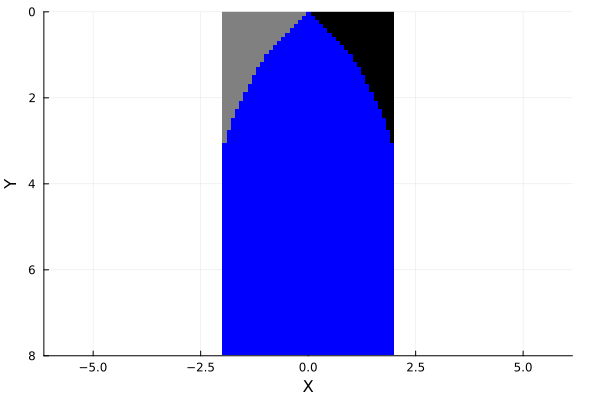

In [48]:
using Plots
n_x = length(unique(d.yA))
n_y = length(unique(d.alpha))
Z = reshape(d.color, n_y, n_x)

heatmap(unique(log2.(d.yA)), unique(d.alpha), Z,
        xlabel="X", ylabel="Y", colorbar_title="Color")

In [29]:
first(d,5)

Row,alpha,beta,lambda,yA,yB,naive_flexible_fitness
,Float64,Int64,Int64,Float64,Int64,Float64
1,0.0,0,1,0.25,1,0.3125
2,0.1,0,1,0.25,1,0.327381
3,0.2,0,1,0.25,1,0.340909
4,0.3,0,1,0.25,1,0.353261
5,0.4,0,1,0.25,1,0.364583


In [20]:
alpha = collect(1:1:6)
yA = 2.0 .^ collect(0:1:3)


d = DataFrame(collect(Iterators.product(alpha,yA)))

ArgumentError: ArgumentError: `DataFrame` constructor from a `Matrix` requires passing :auto as a second argument to automatically generate column names: `DataFrame(matrix, :auto)`

In [5]:
yA

2-element Vector{Float64}:
 0.25
 1.0

In [15]:
e = Environment(2,["bad","good"],[0 1; 1 0])
s = randomStrategy(2)

Strategy(2, 0.46176849430771805, 0.793239836931838, 0.4194425121337625, 0.6490703140570134, 0.6684174445632027, 0.32632679827526145, 0.43912897720595057, 0.6407981899153892)

In [16]:
a = analyzeStrategy(e, s, Dict("B" => 2.0, "C" => 1.0, "gamma" => 1e-6, "n" => 2, "alpha" => 3.0, "beta"=>1.0), allStates(e, 2))

Dict{String, Any} with 4 entries:
  "fitness"  => 0.193788
  "M"        => [-5.54708 4.54708 … 0.0 0.0; 1.8121 -5.24288 … 1.0 0.0; … ; 0.0…
  "analysis" => Dict{Any, Any}()
  "states"   => 6×10 DataFrame…

In [17]:
a["states"]

Row,A,B,env_state,env,activity,perCapitaYield,yield,timeSpent,fitnessContribution,leaveRate
,Int64,Int64,Int64,String,Int64,Float64,Float64,Float64,Float64,Float64
1,2,0,1,bad,2,-1.0,-2.0,0.0924182,-0.184836,5.54708
2,1,1,1,bad,1,-1.0,-1.0,0.235919,-0.235919,5.24288
3,0,2,1,bad,0,-1.0,-0.0,0.171663,-0.0,4.39491
4,2,0,2,good,2,2.0,4.0,0.0851414,0.340566,6.41209
5,1,1,2,good,1,2.0,2.0,0.233882,0.467765,5.80236
6,0,2,2,good,0,2.0,0.0,0.180976,0.0,4.64887


In [20]:
allStates(e,3)["envloc"]

Dict{Any, Any} with 4 entries:
  4 => Any[4, 8]
  2 => Any[2, 6]
  3 => Any[3, 7]
  1 => Any[1, 5]

In [32]:
function states(n)
    d = DataFrame(typeA = repeat(0:n, 2),
    environment = vcat(fill("A", n+1), fill("B", n+1)))
    d.typeB = n .- d.typeA
    return d 
end

states (generic function with 1 method)

In [33]:
states(5)

Row,typeA,environment,typeB
,Int64,String,Int64
1,0,A,5
2,1,A,4
3,2,A,3
4,3,A,2
5,4,A,1
6,5,A,0
7,0,B,5
8,1,B,4
9,2,B,3


In [19]:
function createSystemMarkovChain(n, alpha, beta, gamma, lambda, s)
    m = zeros(2*n+2, 2*n+2)
    for i in 1:(n+1)
        m[i,i] += -lambda
        m[n+1+i, i] += lambda
        m[n+1+i, n+1+i] += -lambda
        m[i, n+1+i] += lambda
    end
    function pIncreaseA(x,env) # probability for A to increase given x individuals in env
        if env == "A"
            return alpha*(n-x)*s.piAA + beta*x*(n-x)*s.thetaAA + beta*(n-x)*(n-x)*s.thetaBA + (n-x)*gamma
        elseif env == "B"
            return alpha*(n-x)*s.piBA + beta*x*(n-x)*s.thetaAA + beta*(n-x)*(n-x)*s.thetaBA + (n-x)*gamma
        end
    end
    function pDecreaseA(x, env)
        if env == "A"
            return alpha*x*s.piAB + beta*x*(n-x)*s.thetaBB + beta*x*x*s.thetaAB + x*gamma
        elseif env == "B"
            return alpha*x*s.piBB + beta*x*(n-x)*s.thetaBB + beta*x*x*s.thetaAB + x*gamma
        end    
    end
    for i in 1:(n)
        m[i,i+1] += pDecreaseA(i, "A")
        m[i+1, i+1] += -pDecreaseA(i, "A")
        m[i+1,i] += pIncreaseA(i-1, "A")
        m[i,i] += -pIncreaseA(i-1, "A")
        m[n+1+i,n+1+i+1] += pDecreaseA(i, "B")
        m[n+1+i+1,n+1+i+1] += -pDecreaseA(i, "B")
        m[n+1+i+1,n+1+i] += pIncreaseA(i-1, "B")
        m[n+1+i,n+1+i] += -pIncreaseA(i-1, "B")
    end
    return m
end

createSystemMarkovChain (generic function with 2 methods)

In [1]:
struct Strategy
    piAA::Float64
    piAB::Float64
    piBA::Float64
    piBB::Float64
    thetaAA::Float64
    thetaAB::Float64
    thetaBA::Float64
    thetaBB::Float64
end

In [24]:
m1 = createSystemMarkovChain(4, 1, 0, 0.001, 1, Strategy(1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0))

10×10 Matrix{Float64}:
 -5.004   0.001   0.0     0.0     0.0    …   0.0     0.0     0.0     0.0
  4.004  -4.004   0.002   0.0     0.0        1.0     0.0     0.0     0.0
  0.0     3.003  -3.004   0.003   0.0        0.0     1.0     0.0     0.0
  0.0     0.0     2.002  -2.004   0.004      0.0     0.0     1.0     0.0
  0.0     0.0     0.0     1.001  -1.004      0.0     0.0     0.0     1.0
  1.0     0.0     0.0     0.0     0.0    …   1.001   0.0     0.0     0.0
  0.0     1.0     0.0     0.0     0.0       -2.004   2.002   0.0     0.0
  0.0     0.0     1.0     0.0     0.0        0.003  -3.004   3.003   0.0
  0.0     0.0     0.0     1.0     0.0        0.0     0.002  -4.004   4.004
  0.0     0.0     0.0     0.0     1.0        0.0     0.0     0.001  -5.004

In [27]:
using LinearAlgebra
function stationaryState(mat)
    #println(mat)
    n = nullspace(mat)
    if size(n,2) > 1
        println(mat)
        u = findfirst(i -> sameSign(n[:,i]),1:size(n,2)) # there may be multiple columns; find the first column where all entries have the same sign
        n = n[:,u]
    end
    s = n / sum(n)
    return(vec(s))
end


stationaryState (generic function with 1 method)

In [47]:

function fitnessFiniteModel(n,alpha,beta,gamma,lambda,s,yA,yB)
    m = createSystemMarkovChain(n, alpha, beta, gamma, lambda, s)
    v = stationaryState(m)
    return sum(v .* [collect(0:n) .* yA ;  reverse(collect(0:n)) .* yB])/n
end

fitnessFiniteModel (generic function with 1 method)

In [6]:
fitnessFiniteModel(1, 3, 100, 0.001, 1, Strategy(1,0,0,1,1,0,0,0), 1, 1)

0.7998800479808079

In [46]:
n = 4 
yA = 1
yB = 1
[collect(0:n) .* yA ;  reverse(collect(0:n)) .* yB]

10-element Vector{Int64}:
 0
 1
 2
 3
 4
 4
 3
 2
 1
 0

In [8]:
using DataFrames
using Plots

1
1
1
1
1
1


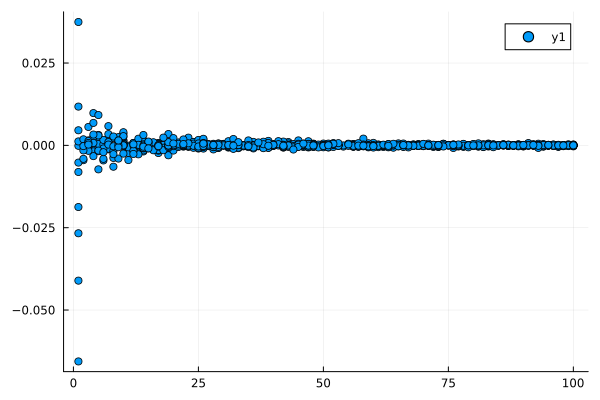

In [9]:
d = DataFrame(alpha = [], beta = [], n = [], piAA = [], piAB = [], piBA = [], piBB = [], thetaAA = [], thetaAB = [], thetaBA = [], thetaBB =[], f1=[], f2=[])
for i in 1:1000
    s = Strategy(rand(),rand(),rand(),rand(),rand(),rand(),rand(),rand())
    alpha = rand()*50
    beta = rand()*5
    lambda = 1
    gamma = 0
    yA = 1
    yB = 1
    n = rand(1:100)
    f1 = fitnessInfiniteModel(alpha,beta,lambda,s,yA,yB)
    f2 = fitnessFiniteModel(n,alpha,beta/n,gamma,lambda,s,yA,yB)
    if abs(f1-f2) > 0.01
        println(n)
    end
    push!(d, (alpha=alpha, beta=beta, n =n, piAA = s.piAA, piAB = s.piAB, piBA= s.piBA, piBB=s.piBB, thetaAA=s.thetaAA,thetaAB=s.thetaAB, thetaBA=s.thetaBA, thetaBB=s.thetaBB, f1=f1, f2=f2))
end
scatter(d.n,d.f1-d.f2)

In [76]:
f1

0.49706802333601807

In [85]:
minimum(f1s .- f2s)

-0.018261196508140676

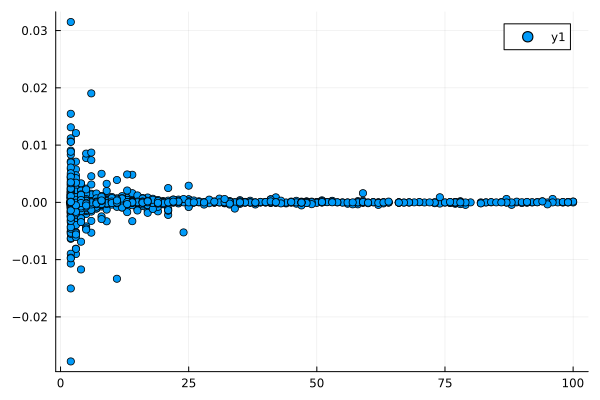

In [69]:
floor(100^rand())

46.0

In [40]:
vcat([0,1,2,3,4],[4,3,2,1,0])

10-element Vector{Int64}:
 0
 1
 2
 3
 4
 4
 3
 2
 1
 0

In [37]:
(0:n) .* yB

0:1:4